# 12. Análisis final del experimento

**Objetivo:** integrar los resultados obtenidos durante la auditoría del dataset, la construcción de la arquitectura 1D-CNN, el entrenamiento, la evaluación y el análisis de importancia de variables.

Este notebook no realiza un nuevo entrenamiento. Utiliza exclusivamente los resultados generados en los notebooks anteriores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

BASE = Path("../../resultados/nuevo_experimento")
FIG_DIR = BASE / "figuras"
TAB_DIR = BASE / "tablas"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

print("Directorio de resultados:", BASE)

Directorio de resultados: ..\..\resultados\nuevo_experimento


## 1. Características del dataset

El experimento parte de un conjunto original de 70,000 registros. La auditoría identificó registros que incumplían los criterios operacionales de consistencia definidos para el experimento.

Después del filtrado se conservaron 68,615 registros y posteriormente se seleccionó una muestra estratificada de 15,000 observaciones para el entrenamiento.

In [2]:
dataset_resumen = pd.DataFrame({
    "Etapa": [
        "Dataset original",
        "Dataset después de auditoría",
        "Muestra utilizada"
    ],
    "Registros": [
        70000,
        68615,
        15000
    ]
})

print(dataset_resumen.to_string(index=False))

dataset_resumen.to_csv(
    TAB_DIR / "resumen_dataset_final.csv",
    index=False
)

                       Etapa  Registros
            Dataset original      70000
Dataset después de auditoría      68615
           Muestra utilizada      15000


## 2. Variables utilizadas

El identificador `id` no se utiliza como variable predictora. La variable objetivo es `cardio`.

Se utilizan 11 variables clínicas:
edad, sexo, altura, peso, presión sistólica, presión diastólica, colesterol, glucosa, tabaquismo, consumo de alcohol y actividad física.

In [3]:
variables = [
    "Edad",
    "Sexo",
    "Altura",
    "Peso",
    "Presión sistólica",
    "Presión diastólica",
    "Colesterol",
    "Glucosa",
    "Tabaquismo",
    "Consumo de alcohol",
    "Actividad física"
]

print("Número de variables predictoras:", len(variables))

for i, variable in enumerate(variables, start=1):
    print(f"{i}. {variable}")

Número de variables predictoras: 11
1. Edad
2. Sexo
3. Altura
4. Peso
5. Presión sistólica
6. Presión diastólica
7. Colesterol
8. Glucosa
9. Tabaquismo
10. Consumo de alcohol
11. Actividad física


## 3. Arquitectura final

La arquitectura utilizada contiene seis capas y fue diseñada para mantener el número total de parámetros dentro del intervalo establecido de 30,000 a 50,000 parámetros.

In [4]:
arquitectura = pd.DataFrame({
    "Capa": [
        "Conv1D",
        "Conv1D",
        "GlobalAveragePooling1D",
        "Dense",
        "Dropout",
        "Dense"
    ],
    "Salida": [
        "(None, 11, 32)",
        "(None, 11, 96)",
        "(None, 96)",
        "(None, 256)",
        "(None, 256)",
        "(None, 1)"
    ],
    "Parámetros": [
        128,
        9312,
        0,
        24832,
        0,
        257
    ]
})

print(arquitectura.to_string(index=False))
print()
print("Total de parámetros:", arquitectura["Parámetros"].sum())

assert arquitectura["Parámetros"].sum() == 34529

arquitectura.to_csv(
    TAB_DIR / "arquitectura_final_resumen.csv",
    index=False
)

                  Capa         Salida  Parámetros
                Conv1D (None, 11, 32)         128
                Conv1D (None, 11, 96)        9312
GlobalAveragePooling1D     (None, 96)           0
                 Dense    (None, 256)       24832
               Dropout    (None, 256)           0
                 Dense      (None, 1)         257

Total de parámetros: 34529


## 4. Desempeño del modelo

Los resultados corresponden al modelo entrenado sobre la muestra de 15,000 registros.

El entrenamiento utilizó parada temprana y finalizó en la época 66.

In [5]:
metricas = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Valor": [
        0.7311,
        0.7326,
        0.7188,
        0.7256,
        0.7885
    ]
})

metricas["Porcentaje"] = metricas["Valor"] * 100

print(metricas.to_string(index=False))

metricas.to_csv(
    TAB_DIR / "metricas_finales_resumen.csv",
    index=False
)

  Métrica  Valor  Porcentaje
 Accuracy 0.7311       73.11
Precision 0.7326       73.26
   Recall 0.7188       71.88
 F1-score 0.7256       72.56
  ROC-AUC 0.7885       78.85


## 5. Importancia de variables

El análisis complementario mediante árbol de decisión mostró una mayor importancia relativa de la presión sistólica, seguida por la edad y el colesterol.

Este resultado no representa los pesos internos de la CNN. Se utiliza únicamente como herramienta complementaria de interpretación.

In [6]:
importancia = pd.DataFrame({
    "Variable": [
        "Presión sistólica",
        "Edad",
        "Colesterol",
        "Peso",
        "Presión diastólica"
    ],
    "Importancia": [
        0.747432,
        0.151009,
        0.074941,
        0.010035,
        0.008521
    ]
})

print(importancia.to_string(index=False))

print()
print(
    "Variable con mayor importancia:",
    importancia.iloc[0]["Variable"]
)

          Variable  Importancia
 Presión sistólica     0.747432
              Edad     0.151009
        Colesterol     0.074941
              Peso     0.010035
Presión diastólica     0.008521

Variable con mayor importancia: Presión sistólica


## 6. Integración de resultados

La siguiente tabla resume los principales elementos del experimento.

In [7]:
resumen = pd.DataFrame({
    "Elemento": [
        "Registros originales",
        "Registros después de auditoría",
        "Registros utilizados",
        "Variables predictoras",
        "Capas del modelo",
        "Parámetros",
        "Épocas ejecutadas",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Resultado": [
        "70,000",
        "68,615",
        "15,000",
        "11",
        "6",
        "34,529",
        "66",
        "73.11 %",
        "73.26 %",
        "71.88 %",
        "72.56 %",
        "78.85 %"
    ]
})

print(resumen.to_string(index=False))

resumen.to_csv(
    TAB_DIR / "resumen_experimento_final.csv",
    index=False
)

                      Elemento Resultado
          Registros originales    70,000
Registros después de auditoría    68,615
          Registros utilizados    15,000
         Variables predictoras        11
              Capas del modelo         6
                    Parámetros    34,529
             Épocas ejecutadas        66
                      Accuracy   73.11 %
                     Precision   73.26 %
                        Recall   71.88 %
                      F1-score   72.56 %
                       ROC-AUC   78.85 %


## 7. Visualización del desempeño

Se genera una representación conjunta de las métricas principales del modelo.

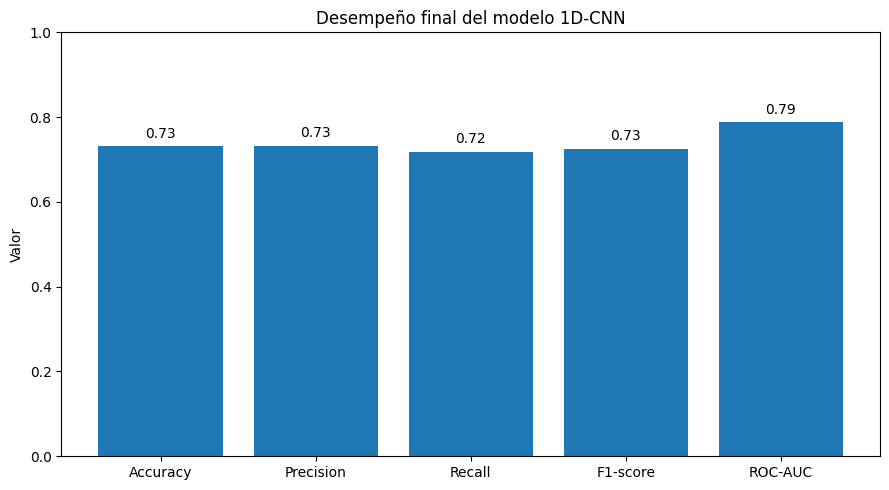

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    metricas["Métrica"],
    metricas["Valor"]
)

ax.set_ylim(0, 1)
ax.set_ylabel("Valor")
ax.set_title("Desempeño final del modelo 1D-CNN")

for i, value in enumerate(metricas["Valor"]):
    ax.text(
        i,
        value + 0.02,
        f"{value:.2f}",
        ha="center"
    )

fig.tight_layout()

fig.savefig(
    FIG_DIR / "metricas_finales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Interpretación de los resultados

El modelo obtuvo una Accuracy de 73.11 %, mientras que Precision, Recall y F1-score alcanzaron 73.26 %, 71.88 % y 72.56 %, respectivamente. El ROC-AUC fue de 78.85 %, lo que indica una capacidad de discriminación superior al azar.

La arquitectura contiene 34,529 parámetros, ubicándose dentro del intervalo de 30,000 a 50,000 parámetros establecido para el experimento.

El análisis complementario de importancia de variables identificó a la presión sistólica como la variable con mayor importancia relativa en el árbol de decisión, seguida por la edad y el colesterol.

Estos resultados deben interpretarse dentro de las condiciones experimentales establecidas: una muestra estratificada de 15,000 registros, las reglas de consistencia definidas y la arquitectura 1D-CNN modificada.

## 9. Conclusión experimental

Se implementó una arquitectura 1D-CNN modificada para la clasificación de enfermedad cardiovascular utilizando 15,000 registros seleccionados de un conjunto de 70,000 observaciones. Después de la auditoría se conservaron 68,615 registros válidos y se obtuvo una muestra estratificada reproducible.

La arquitectura final está compuesta por dos capas Conv1D, una capa GlobalAveragePooling1D, una capa Dense, una capa Dropout y una capa Dense de salida. El modelo contiene 34,529 parámetros, cumpliendo el intervalo de complejidad establecido.

El desempeño obtenido fue de 73.11 % de Accuracy, 73.26 % de Precision, 71.88 % de Recall, 72.56 % de F1-score y 78.85 % de ROC-AUC.

En conjunto, el experimento proporciona una implementación reproducible y documentada del modelo propuesto, con una arquitectura de menor complejidad y un análisis complementario de las variables clínicas utilizadas.

## 10. Verificación final

In [9]:
assert len(dataset_resumen) == 3
assert len(variables) == 11
assert arquitectura["Parámetros"].sum() == 34529
assert len(metricas) == 5
assert abs(metricas.loc[0, "Valor"] - 0.7311) < 1e-9
assert abs(metricas.loc[4, "Valor"] - 0.7885) < 1e-9

print("==============================================")
print("VERIFICACIÓN FINAL SATISFACTORIA")
print("==============================================")
print("Dataset utilizado: 15,000 registros")
print("Variables predictoras: 11")
print("Parámetros: 34,529")
print("Accuracy: 73.11 %")
print("F1-score: 72.56 %")
print("ROC-AUC: 78.85 %")
print("==============================================")

VERIFICACIÓN FINAL SATISFACTORIA
Dataset utilizado: 15,000 registros
Variables predictoras: 11
Parámetros: 34,529
Accuracy: 73.11 %
F1-score: 72.56 %
ROC-AUC: 78.85 %
